In [31]:
import numpy as np
import matplotlib.pyplot as plt
import time

import essrs

In [32]:
MU = np.array([0.0, 0.0])
SIGMA = np.array([1.0, 1.0])
CORRELATION = np.array([0.9])

In [33]:
N_SAMPLES: int = 30
N_WALKERS: int = 1000
N_PARAMETERS: int = 2
N_BURN_IN: int = 100
N_THREADS: int = 1
N_THINNING_PER_SAMPLE: int = None

In [34]:
burn_move = essrs.moves.hybrid_ddc_move(one_in_n=10)
sampler_move = essrs.moves.differential_move()
config = essrs.EnsembleConfig(
    n_samples=N_SAMPLES,
    n_walkers=N_WALKERS,
    n_parameters=N_PARAMETERS,
    n_burn_in=N_BURN_IN,
    n_threads=N_THREADS,
    n_thinning_per_sample=N_THINNING_PER_SAMPLE
)

In [35]:
ics = np.random.normal(loc=0.0, scale=1.0, size=(N_WALKERS, 2))

In [36]:
model = essrs.model.toy.normal_nd(
    n_dimensions=2,
    mu=MU,
    sigma=SIGMA,
    correlation=CORRELATION
)

start = time.perf_counter()
fit, ll = essrs.run_mcmc(
    log_likelihood=model,
    config=config,
    burn_in_move=burn_move,
    sampling_move=sampler_move,
    initial_conditions=ics
)
elapsed = time.perf_counter() - start
print(f"SAMPLING TIME :: {elapsed:.3f} seconds")

INITIALISED...
SAMPLING TIME :: 0.128 seconds


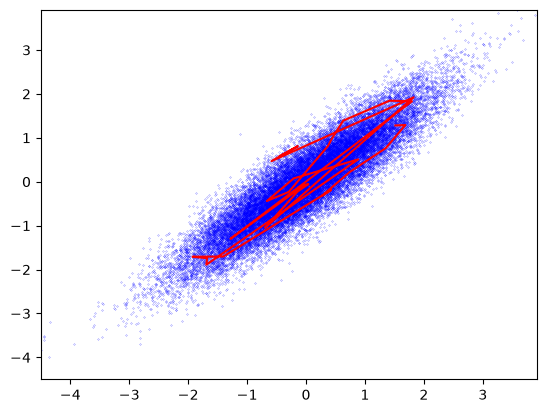

In [37]:
min_max = [np.amin(fit), np.amax(fit)]

plt.figure()
plt.scatter(fit[:,:,0].ravel(), fit[:,:,1].ravel(), color="b", s=0.1, marker=".")
plt.plot(fit[:, 1, 0], fit[:, 1, 1], color="r")
plt.xlim(min_max)
plt.ylim(min_max)
plt.show()